# 03 — Custom CNN (from scratch)

Four conv-BN-ReLU blocks (32→64→128→256), max-pool, global average pool, dropout, 3-class head.
No ImageNet weights. Metrics below are from the real training run, not a re-train.


In [1]:
from pathlib import Path
import json
from IPython.display import Image, display

from ml.engine.experiment_log import load_experiment_record
from ml.models import CustomCNN

ROOT = Path.cwd() if (Path.cwd() / "reports").exists() else Path.cwd().parent
rec = load_experiment_record(ROOT / "reports" / "experiments", "custom_cnn")
print("experiment_id:", rec["experiment_id"])
print("epochs in history:", len(rec["history"]), "configured:", rec["epochs_configured"])
print("batch_size:", rec["batch_size"], "lr:", rec["learning_rate"])
print("seconds:", round(rec["training_seconds"], 1))
print("params:", sum(p.numel() for p in CustomCNN().parameters()))
print(CustomCNN())


experiment_id: custom_cnn_20260917T194811Z
epochs in history: 7 configured: {'batch_size': 32, 'lr': 0.001, 'weight_decay': 0.0001, 'epochs': 8, 'early_stopping_patience': 3, 'epochs_head': 8, 'epochs_finetune': 0, 'finetune_lr': 0.0001}
batch_size: 32 lr: 0.001
seconds: 30084.8
params: 1173987
CustomCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64

VAL  acc=0.5852  macro-F1=0.5097
TEST acc=0.6294  macro-F1=0.5185
{
  "little_or_none": {
    "precision": 0.8410237923576064,
    "recall": 0.6471567267683772,
    "f1": 0.731462611694623,
    "support": 3605
  },
  "mild": {
    "precision": 0.1648540354894104,
    "recall": 0.4155844155844156,
    "f1": 0.2360655737704918,
    "support": 693
  },
  "severe": {
    "precision": 0.6004978220286248,
    "recall": 0.5273224043715847,
    "f1": 0.5615362234506838,
    "support": 1830
  }
}


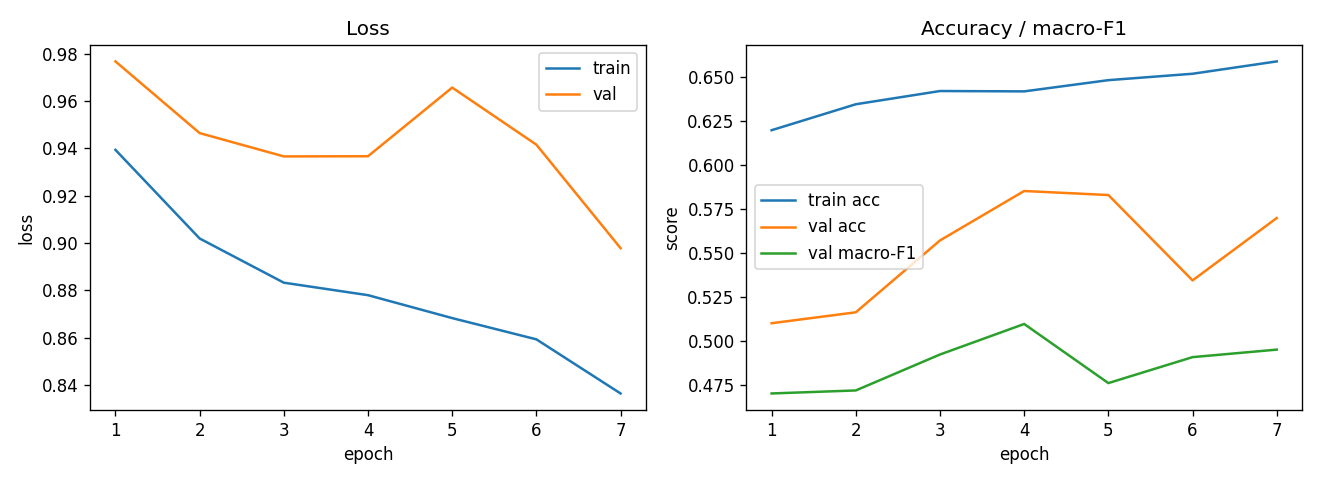

In [2]:
vm, tm = rec["val_metrics"], rec["test_metrics"]
print("VAL  acc={:.4f}  macro-F1={:.4f}".format(vm["accuracy"], vm["macro_f1"]))
print("TEST acc={:.4f}  macro-F1={:.4f}".format(tm["accuracy"], tm["macro_f1"]))
print(json.dumps(vm["per_class"], indent=2))
curve = Path(rec["curves"])
display(Image(filename=str(curve))) if curve.exists() else print("missing", curve)
